In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
dataset = pd.read_csv('Mall_Customers.csv')

In [3]:
dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [4]:
X = dataset.iloc[:, 3:5].values

In [5]:
X

array([[ 15,  39],
       [ 15,  81],
       [ 16,   6],
       [ 16,  77],
       [ 17,  40],
       [ 17,  76],
       [ 18,   6],
       [ 18,  94],
       [ 19,   3],
       [ 19,  72],
       [ 19,  14],
       [ 19,  99],
       [ 20,  15],
       [ 20,  77],
       [ 20,  13],
       [ 20,  79],
       [ 21,  35],
       [ 21,  66],
       [ 23,  29],
       [ 23,  98],
       [ 24,  35],
       [ 24,  73],
       [ 25,   5],
       [ 25,  73],
       [ 28,  14],
       [ 28,  82],
       [ 28,  32],
       [ 28,  61],
       [ 29,  31],
       [ 29,  87],
       [ 30,   4],
       [ 30,  73],
       [ 33,   4],
       [ 33,  92],
       [ 33,  14],
       [ 33,  81],
       [ 34,  17],
       [ 34,  73],
       [ 37,  26],
       [ 37,  75],
       [ 38,  35],
       [ 38,  92],
       [ 39,  36],
       [ 39,  61],
       [ 39,  28],
       [ 39,  65],
       [ 40,  55],
       [ 40,  47],
       [ 40,  42],
       [ 40,  42],
       [ 42,  52],
       [ 42,  60],
       [ 43,

In [6]:
from sklearn.cluster import AffinityPropagation
num_clusters_list = []
preferences = np.linspace(-100, 0, 10)

for preference in preferences:
    affinity_propagation = AffinityPropagation(preference=preference)
    affinity_propagation.fit(X)
    num_clusters = len(np.unique(affinity_propagation.labels_))
    num_clusters_list.append(num_clusters)

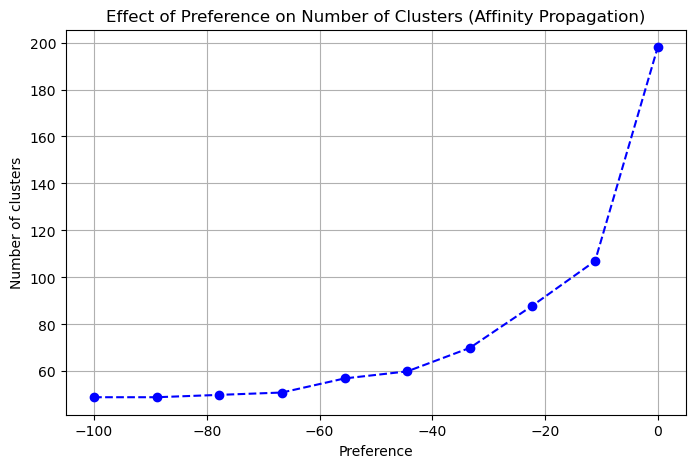

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(preferences, num_clusters_list, marker='o', linestyle='--', color='b')
plt.title('Effect of Preference on Number of Clusters (Affinity Propagation)')
plt.xlabel('Preference')
plt.ylabel('Number of clusters')
plt.grid(True)
plt.show()

In [8]:
num_clusters_list

[49, 49, 50, 51, 57, 60, 70, 88, 107, 198]

In [9]:
from sklearn.cluster import AffinityPropagation
affinity_propagation = AffinityPropagation()
y_affinity = affinity_propagation.fit_predict(X)

In [10]:
y_affinity

array([ 2,  1,  0,  1,  2,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  2,
        1,  2,  1,  2,  1,  0,  1,  0,  1,  2,  3,  2,  1,  0,  1,  0,  1,
        0,  1,  0,  1,  2,  1,  2,  1,  2,  3,  2,  3,  3,  3,  3,  3,  3,
        3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,
        3,  3,  3,  3,  3,  3,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,
        4,  4,  4,  4,  4,  4,  5,  4,  5,  5,  4,  4,  4,  5,  4,  5,  4,
        4,  4,  4,  5,  4,  4,  5,  4,  4,  4,  5,  5,  4,  4,  5,  4,  5,
        4,  4,  5,  4,  7,  5,  8,  5,  7,  6,  8,  6,  8,  5,  8,  6,  7,
        6,  8,  6,  8,  6,  7,  5,  7,  6,  7,  5,  8,  6,  7,  6,  7,  6,
        8,  6,  7,  6,  8,  6,  8,  5,  7,  6,  7,  6,  8,  6,  7, 10,  8,
        6,  8,  6,  7,  6,  7,  6,  8, 10,  9, 10,  9, 10,  9, 10,  9, 10,
        9, 10,  9, 10,  9, 10,  9, 10,  9, 10,  9, 10,  9])

In [11]:
supervised=dataset

In [12]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [13]:
supervised['Cluster_group']=y_affinity

In [14]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,1,Male,19,15,39,2
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,1
4,5,Female,31,17,40,2
...,...,...,...,...,...,...
195,196,Female,35,120,79,9
196,197,Female,45,126,28,10
197,198,Male,32,126,74,9
198,199,Male,32,137,18,10


In [15]:
supervised.to_csv("cluster_Affinity_Propagation.csv", index=False)

In [16]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,1,Male,19,15,39,2
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,1
4,5,Female,31,17,40,2
...,...,...,...,...,...,...
195,196,Female,35,120,79,9
196,197,Female,45,126,28,10
197,198,Male,32,126,74,9
198,199,Male,32,137,18,10


In [17]:
dir(AffinityPropagation)

['__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__sklearn_tags__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_build_request_for_signature',
 '_check_feature_names',
 '_check_n_features',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_estimator_type',
 '_get_default_requests',
 '_get_doc_link',
 '_get_metadata_request',
 '_get_param_names',
 '_get_tags',
 '_more_tags',
 '_parameter_constraints',
 '_repr_html_',
 '_repr_html_inner',
 '_repr_mimebundle_',
 '_validate_data',
 '_validate_params',
 'fit',
 'fit_predict',
 'get_metadata_routing',
 'get_params',

In [18]:
cluster_centers_indices = affinity_propagation.cluster_centers_indices_
cluster_centers = X[cluster_centers_indices]

In [19]:
cluster_centers

array([[ 25,   5],
       [ 28,  82],
       [ 28,  32],
       [ 46,  51],
       [ 60,  52],
       [ 67,  40],
       [ 77,  12],
       [ 78,  90],
       [ 78,  73],
       [103,  85],
       [103,  23]])

In [20]:
y_affinity

array([ 2,  1,  0,  1,  2,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  2,
        1,  2,  1,  2,  1,  0,  1,  0,  1,  2,  3,  2,  1,  0,  1,  0,  1,
        0,  1,  0,  1,  2,  1,  2,  1,  2,  3,  2,  3,  3,  3,  3,  3,  3,
        3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,
        3,  3,  3,  3,  3,  3,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,
        4,  4,  4,  4,  4,  4,  5,  4,  5,  5,  4,  4,  4,  5,  4,  5,  4,
        4,  4,  4,  5,  4,  4,  5,  4,  4,  4,  5,  5,  4,  4,  5,  4,  5,
        4,  4,  5,  4,  7,  5,  8,  5,  7,  6,  8,  6,  8,  5,  8,  6,  7,
        6,  8,  6,  8,  6,  7,  5,  7,  6,  7,  5,  8,  6,  7,  6,  7,  6,
        8,  6,  7,  6,  8,  6,  8,  5,  7,  6,  7,  6,  8,  6,  7, 10,  8,
        6,  8,  6,  7,  6,  7,  6,  8, 10,  9, 10,  9, 10,  9, 10,  9, 10,
        9, 10,  9, 10,  9, 10,  9, 10,  9, 10,  9, 10,  9])

In [21]:
supervised.columns[3]

'Annual Income (k$)'

In [22]:
supervised.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)', 'Cluster_group'],
      dtype='object')

C:\Anaconda 3\Lib\site-packages\seaborn\regression.py:598: UserWarning: legend_out is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


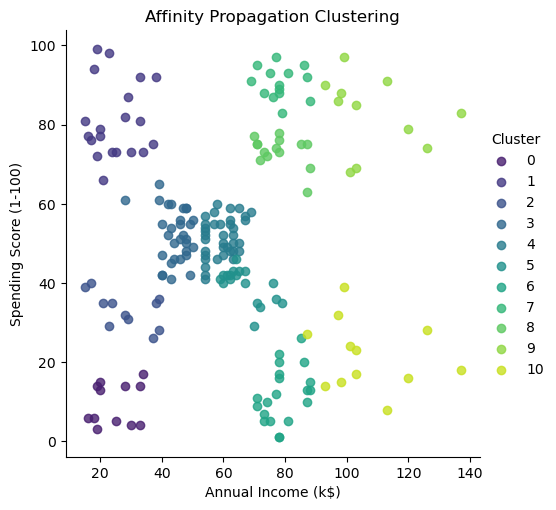

In [23]:
import seaborn as sns
x_col = supervised.columns[3]
y_col = supervised.columns[4]
affinity_propagation = AffinityPropagation()
supervised['Cluster'] = affinity_propagation.fit_predict(supervised[[x_col, y_col]])
facet = sns.lmplot(data=supervised, x=x_col, y=y_col, hue='Cluster', 
                   fit_reg=False, legend=True, legend_out=True, palette="viridis")
plt.title('Affinity Propagation Clustering')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.show()

In [24]:
import pickle
pickle.dump(affinity_propagation,open("affinity_propagation_model.pkl", "wb"))
print("Model saved successfully!")

Model saved successfully!


In [25]:
loaded_model = pickle.load(open("affinity_propagation_model.pkl", "rb"))
print("Model loaded successfully!")

Model loaded successfully!


In [26]:
y_affinity = loaded_model.labels_
print(y_affinity)

[ 2  1  0  1  2  1  0  1  0  1  0  1  0  1  0  1  2  1  2  1  2  1  0  1
  0  1  2  3  2  1  0  1  0  1  0  1  0  1  2  1  2  1  2  3  2  3  3  3
  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3
  3  3  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  5  4  5  5  4
  4  4  5  4  5  4  4  4  4  5  4  4  5  4  4  4  5  5  4  4  5  4  5  4
  4  5  4  7  5  8  5  7  6  8  6  8  5  8  6  7  6  8  6  8  6  7  5  7
  6  7  5  8  6  7  6  7  6  8  6  7  6  8  6  8  5  7  6  7  6  8  6  7
 10  8  6  8  6  7  6  7  6  8 10  9 10  9 10  9 10  9 10  9 10  9 10  9
 10  9 10  9 10  9 10  9]


In [27]:
new_data = np.array([[15, 39]])
cluster_centers = loaded_model.cluster_centers_
center_indices = loaded_model.cluster_centers_indices_
if cluster_centers is None:
    raise ValueError("The model has no cluster centers.")
distances = np.linalg.norm(cluster_centers - new_data,axis=1)
nearest_center = np.argmin(distances)
center_labels = loaded_model.labels_[center_indices]
predicted_cluster = center_labels[nearest_center]
print("Predicted Cluster:", predicted_cluster)

Predicted Cluster: 2
